# Probabilistic robotics lab: tracking a moving vehicle

**Name:** …  
**Version:** 1.0 — 25 October 2026

Estimate a vehicle's position and velocity from noisy sensor readings. Use a
Kalman filter (KF), investigate its uncertainty, and extend it to a nonlinear
range sensor with an extended Kalman filter (EKF).

## How to work

- Complete **all four tasks** in this notebook. There are no optional tasks and
  no separate report.
- Run cells in order. **Provided code** is ready to run. In **Your code** cells,
  write the requested implementation. Function stubs raise `NotImplementedError`
  until you replace their bodies. Comment-only cells are places for your analysis.
- Keep the supplied data, seed and settings, except where a task asks for a change.
  Use NumPy arrays and short functions. Do not use a ready-made KF/EKF package.
- Answer the numbered questions below each task using your own results. Usually
  1–3 sentences per question are enough; no word count is required.
- Label plot axes with units and identify each line. Use tables for numerical
  comparisons. Do not paste long arrays into your answers.
- You may refer to your notebook during the written defense. Be ready to explain
  your implementation, results and the limits of your conclusions.

This notebook creates all its data. No separate dataset file is needed.


## Setup — provided code

Use JupyterHub or a local Jupyter environment. Run the imports below. If a package
is missing, uncomment the `%pip` line, run it, restart the kernel and try again.
On JupyterHub, contact the lecturer if installation is disabled.


In [ ]:
# Run only if an import fails. Then restart the kernel.
# %pip install numpy pandas matplotlib


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
plt.rcParams["figure.dpi"] = 110
print("Imports OK:", "NumPy", np.__version__, "| pandas", pd.__version__)


Imports OK: NumPy 2.4.6 | pandas 3.0.5


## The setting

A vehicle moves along a straight line. Its state is

$$
x_t=\begin{bmatrix}p_t\\v_t\end{bmatrix},
$$

where position pₜ is in metres and velocity vₜ is in metres per second.
This is **one-dimensional movement with a two-component state**.

In Tasks 1–3 the sensor measures position, not velocity. The filter assumes

$$
x_t=F x_{t-1}+w_t,\qquad
F=\begin{bmatrix}1&\Delta t\\0&1\end{bmatrix},\qquad
w_t\sim\mathcal N(0,Q),
$$

$$
z_t=H x_t+e_t,\qquad H=\begin{bmatrix}1&0\end{bmatrix},\qquad
e_t\sim\mathcal N(0,R).
$$

Errors are independent across time, and process and sensor errors are independent.
Here R is a **scalar variance** because there is one measurement per step.

The simulated vehicle sometimes accelerates. Those accelerations are **not given
to the filter**: its constant-velocity model is an approximation during those
periods. We will examine the consequences rather than fit a more complex model.

### Data — provided code

The next cell creates 120 time points: steps **0–119**, one second apart.
`acceleration[t]` applies during the move from step `t - 1` to step `t`.
It is nonzero for steps 30–39 and 75–84, inclusive. Independent position and
velocity disturbances have standard deviations 0.2 m and 0.1 m/s. Position-sensor
noise has standard deviation 2 m.

`truth[:, 0]` and `truth[:, 1]` contain the simulated true states, for plots and
evaluation only. **Never use `truth` or `acceleration` inside a filter.**


In [4]:
rng = np.random.default_rng(SEED)
dt = 1.0
n_steps = 120
time = np.arange(n_steps) * dt

acceleration = np.zeros(n_steps)
acceleration[30:40] = 0.18
acceleration[75:85] = -0.12

truth = np.zeros((n_steps, 2))
truth[0] = [10.0, 1.0]
for t in range(1, n_steps):
    p, v = truth[t - 1]
    a = acceleration[t]
    truth[t, 0] = p + v * dt + 0.5 * a * dt**2 + rng.normal(0, 0.2)
    truth[t, 1] = v + a * dt + rng.normal(0, 0.1)

sensor_sd = 2.0
z_position = truth[:, 0] + rng.normal(0, sensor_sd, n_steps)

data = pd.DataFrame({
    "time (s)": time,
    "true position (m)": truth[:, 0],
    "true velocity (m/s)": truth[:, 1],
    "position reading (m)": z_position,
})
display(data.head())


,time (s),true position (m),true velocity (m/s),position reading (m)
0,0.0,10.000000,1.000000,7.875171
1,1.0,11.060943,0.896002,10.002065
2,2.0,12.107035,0.990058,10.353314
3,3.0,12.706886,0.859840,12.518361
4,4.0,13.592294,0.828216,10.076838


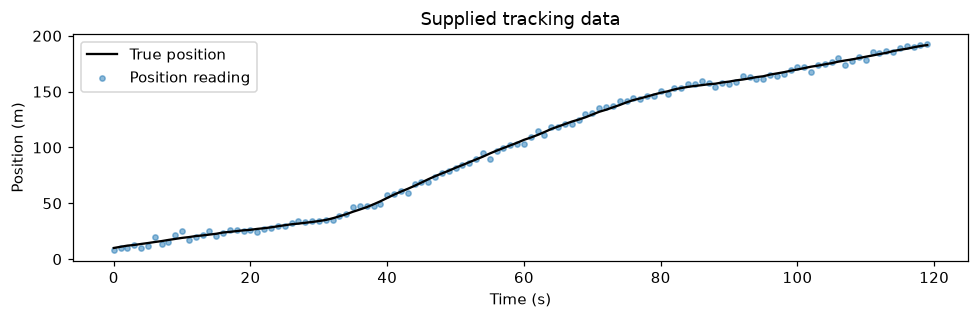

In [11]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(time, truth[:, 0], color="black", label="True position")
ax.scatter(time, z_position, s=12, alpha=0.5, label="Position reading")
ax.set(xlabel="Time (s)", ylabel="Position (m)", title="Supplied tracking data")
ax.legend()
plt.tight_layout()
plt.show()


## Task 1 — implement and evaluate the Kalman filter

**Question:** Can position readings help us estimate both position and velocity?

### 1A. Write the two update functions

Use μ for the estimated state mean and P for its covariance. The bar denotes
the prediction **before** the current reading:

$$
\bar\mu_t=F\mu_{t-1},\qquad \bar P_t=FP_{t-1}F^T+Q.
$$

For the position sensor, correction is

$$
\nu_t=z_t-H\bar\mu_t,\quad S_t=H\bar P_tH^T+R,\quad
K_t=\frac{\bar P_t H^T}{S_t},
$$

$$
\mu_t=\bar\mu_t+K_t\nu_t,\qquad
P_t=\bar P_t-K_t(H\bar P_t).
$$

νₜ is the **innovation**: observed minus predicted measurement. Sₜ is its
variance. The last expression is equivalent to the usual covariance update

$$
P_t=(I-K_tH)\bar P_t.
$$

Use the first form in your code to avoid creating an identity matrix.

**Your code:** replace the bodies of both functions below. Return new arrays;
do not change the input arrays in place. No matrix inverse is needed here.

For simple NumPy code, use these shapes:

| Quantity | Shape |
|---|---|
| `mu`, `mu_pred`, `H`, `K` | `(2,)` — one-dimensional arrays |
| `P`, `P_pred`, `F`, `Q` | `(2, 2)` |
| `z`, `R`, innovation, `S` | scalar |

`@` performs matrix/vector multiplication. A one-dimensional `H` does not need
`.T`: for example, `H @ P_pred @ H` gives a scalar. Use
`np.outer(K, H @ P_pred)` for the matrix subtracted in the covariance update;
ordinary `*` between two vectors would not give this matrix.


In [5]:
def predict(mu, P, F, Q):
    # Return mu_pred, P_pred.
    mu_pred = F @ mu
    P_pred = F @ P @ F.T + Q
    return mu_pred, P_pred


def correct_position(mu_pred, P_pred, z, H, R):
    # Return mu, P after using the position reading z.

    nu = z - H @ mu_pred                     # residual (innovation): observed minus predicted measurement
    S = H @ P_pred @ H + R                   # innovation variance (S)
    K = (P_pred @ H) / S                     # Kalman gain (K)
    mu = mu_pred + K * nu                    # updated state mean
    P = P_pred - np.outer(K, H @ P_pred)     # updated state covariance using the suggested form
    return mu, P


### One-step check — provided code

Run this after completing the functions. It checks one prediction and correction
with fixed inputs. Passing it does not check your later filtering loop.


In [6]:
F_check = np.array([[1.0, 1.0], [0.0, 1.0]])
mu_pred, P_pred = predict(
    np.array([0.0, 0.0]), np.diag([1.0, 4.0]), F_check, np.diag([1.0, 1.0])
)
mu_check, P_check = correct_position(
    mu_pred, P_pred, 2.0, np.array([1.0, 0.0]), 4.0
)
assert np.allclose(mu_pred, [0.0, 0.0])
assert np.allclose(P_pred, [[6.0, 4.0], [4.0, 5.0]])
assert np.allclose(mu_check, [1.2, 0.8])
assert np.allclose(P_check, [[2.4, 1.6], [1.6, 3.4]])
print("One-step check passed.")


One-step check passed.


### 1B. Write the filtering loop

**Provided settings:** initial mean and covariance:

$$
\mu_0=\begin{bmatrix}8\\0\end{bmatrix},\qquad
P_0=\operatorname{diag}(9,1).
$$

Baseline process covariance and sensor variance:

$$
Q=\operatorname{diag}(0.04,0.01),\qquad R=4.
$$

The diagonal entries refer to position and velocity, in that order. These are
variances, not standard deviations. Q describes disturbances **per time step**.

Use the exact time convention below throughout the lab:

1. Row **0** stores the supplied initial belief at time 0. Sensor processing
   starts at step 1: **do not use `z[0]` for correction**.
2. For each `t` from **1** to `len(z) - 1`, predict once, then correct using `z[t]`.
3. Store the **corrected** mean and covariance at row `t`. In Task 3, when the
   reading is missing, store the prediction instead.

**Your code:** construct `F` from `dt` and `H` for a position-only sensor. Complete
`run_kf(z, F, H, Q, R, mu0, P0)` using your two functions. Return:

- `means`: shape `(len(z), 2)`;
- `covariances`: shape `(len(z), 2, 2)`.

Use `np.zeros(...)` to create the output arrays. Start each run from copies of
`mu0` and `P0`; do not continue from the final state of a previous experiment.
All measurements are available for now. Task 3 adds the missing-reading case.
In the returned arrays, `means[t, 0]` is estimated position and
`covariances[t, 0, 0]` is its variance; index 1 refers to velocity.


In [7]:
mu0 = np.array([8.0, 0.0]) #all we need
P0 = np.diag([9.0, 1.0])
Q_base = np.diag([0.04, 0.01])
R_base = sensor_sd**2

# Your code: define F and H using np.array(...).
F = np.array([[1.0, dt],
              [0.0, 1.0]])
H = np.array([1.0, 0.0])

In [8]:
def run_kf(z, F, H, Q, R, mu0, P0):
    # Store the initial belief, then predict and correct at t = 1, 2, ...
    # Return means, covariances.
    n = len(z)
    means = np.zeros((n, 2))
    covariances = np.zeros((n, 2, 2))
    mu, P = mu0.copy(), P0.copy()
    means[0], covariances[0] = mu, P
    for t in range(1, n):
        mu, P = predict(mu, P, F, Q)
        if not np.isnan(z[t]):            
            mu, P = correct_position(mu, P, z[t], H, R)
        means[t], covariances[t] = mu, P
    return means, covariances


### 1C. Evaluate and plot — your code

Run the baseline filter and keep its outputs as `kf_means` and `kf_covariances`.
For **all numerical evaluations in Tasks 1–4, exclude row 0**. It contains the
initial belief, not a filtered result. Otherwise use every stated step, including
the early steps; do not remove a warm-up period.

Use

$$
\operatorname{RMSE}=\sqrt{\frac{1}{n}\sum_t(\widehat y_t-y_t)^2}.
$$

The function below is provided for repeated use. Do not compare a position RMSE
with a velocity RMSE: they have different units.

**Required outputs:**

1. A table with position RMSE for the **raw position readings** and **KF**, and
   velocity RMSE for **KF**. The raw readings have no velocity estimate: use
   `np.nan` for that table entry, not zero.
2. One figure with **two panels**: position against time and velocity against
   time. Show truth, KF mean and its shaded uncertainty band in both panels.
   Add the raw position readings only to the position panel.

For each state component, plot the Gaussian 95% interval

$$
\mu_{t,j}\ \pm\ 1.96\sqrt{P_{t,jj}}.
$$

For position, the standard deviation is `np.sqrt(kf_covariances[:, 0, 0])`.
Use `ax.fill_between(time, lower, upper, alpha=0.2)` to shade a band. Its nominal
95% level relies on the filter's assumptions. Each interval concerns the state
at one time, not a new sensor reading or the whole trajectory at once.


In [22]:
def rmse(estimate, actual):
    return np.sqrt(np.mean((estimate - actual)**2))


,estimate,position RMSE (m),velocity RMSE (m/s)
0,Raw position readings,2.054,NaN
1,KF,1.356,0.437


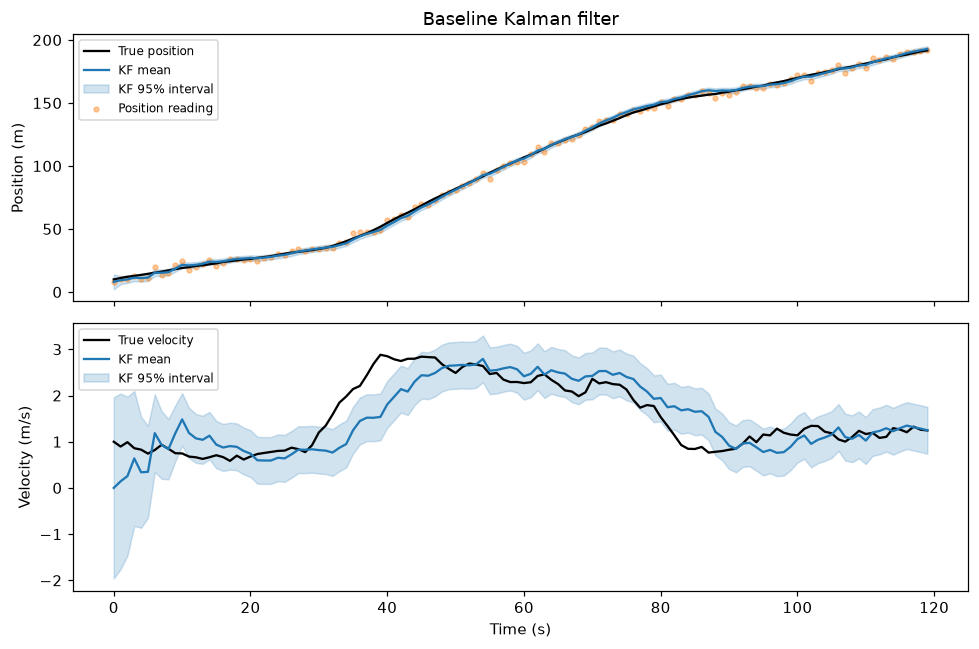

In [23]:
# Your code: run the baseline KF, make the RMSE table and the two-panel figure.
# Keep kf_means and kf_covariances for later comparisons.
kf_means, kf_covariances = run_kf(z_position, F, H, Q_base, R_base, mu0, P0)

ev = slice(1, None)  # exclude row 0 (initial belief)
task1_table = pd.DataFrame({
    "estimate": ["Raw position readings", "KF"],
    "position RMSE (m)": [rmse(z_position[ev], truth[ev, 0]),
                          rmse(kf_means[ev, 0], truth[ev, 0])],
    "velocity RMSE (m/s)": [np.nan, rmse(kf_means[ev, 1], truth[ev, 1])],
})
display(task1_table.round(3))

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
names = [("Position", "m"), ("Velocity", "m/s")]
for j, ax in enumerate(axes):
    sd = np.sqrt(kf_covariances[:, j, j])
    ax.plot(time, truth[:, j], color="black", label=f"True {names[j][0].lower()}")
    ax.plot(time, kf_means[:, j], color="tab:blue", label="KF mean")
    ax.fill_between(time, kf_means[:, j] - 1.96 * sd, kf_means[:, j] + 1.96 * sd,
                    alpha=0.2, color="tab:blue", label="KF 95% interval")
    if j == 0:
        ax.scatter(time, z_position, s=10, alpha=0.4, color="tab:orange",
                   label="Position reading")
    ax.set(ylabel=f"{names[j][0]} ({names[j][1]})")
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_title("Baseline Kalman filter")
axes[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()


### Your answer — Task 1

1. Report both position RMSE values and the KF velocity RMSE. Did filtering
   improve position accuracy on this run? Use the values, not just the plot.
2. The sensor does not measure velocity. Explain how its position readings can
   change the velocity estimate. Refer to position–velocity covariance and gain.
3. Describe one interval where the velocity estimate follows the truth poorly.
   Give its approximate times and relate it to the motion assumed by the filter.

**1.** Over steps 1–119 the raw position readings have a position RMSE of **2.054 m**
(close to the 2 m sensor SD), while the KF has **1.356 m**, about 34% lower, so filtering
did improve position accuracy on this run. The KF velocity RMSE is **0.437 m/s**; the
raw readings give no velocity estimate (NaN in the table).

**2.** The prediction step P(bar) = FPF^T + Q makes position and velocity uncertainty
correlated, because position at t depends on velocity at t − 1 (the off-diagonal of P
settles at about 0.17 m^2/s). The gain K = P_bar H^T/S therefore has a non-zero velocity entry,
P(bar)_pv/S (≈ 0.04 s⁻¹ at steady state, versus aappx. 0.28 for position). When a reading lands
ahead of the predicted position (positive innovation), the filter also raises its
velocity estimate, and repeated same-sign innovations gradually move the velocity.

**3.** During and after the first acceleration, roughly **t = 31–47 s**, the KF velocity
lags badly: the true velocity rises from 0.92 m/s (t = 29) to 2.85 m/s (t = 39), but the
estimate is only 1.54 m/s at t = 39 (error −1.35 m/s, the largest of the run) and only
catches up around t appx. 48 s. The filter assumes constant velocity, treating the 0.18 m/s^2
acceleration as small random process noise (velocity SD 0.1 m/s per step), so it needs
many consistent innovations before it believes the speed has changed. The same lag
appears in reverse during the deceleration around t = 78–90 s.

## Task 2 — change the assumed noise, not the data

**Question:** How do noise assumptions affect accuracy and reported uncertainty?

Reuse the **same** `truth` and `z_position`. Do not generate new data. Run exactly
the five settings below, each starting from the same `mu0` and `P0`.
Scale the whole Q matrix, or the scalar R, as specified. These multipliers
change **variances**, not standard deviations.
Apply each multiplier to the original `Q_base` or `R_base`, not to the previous
run's settings. Keep these baseline variables and Task 1's `kf_means` and
`kf_covariances` unchanged; save the experimental runs separately for plotting.

| Setting | Q multiplier | R multiplier |
|---|---:|---:|
| Baseline | 1 | 1 |
| Lower Q | 0.1 | 1 |
| Higher Q | 10 | 1 |
| Lower R | 1 | 0.1 |
| Higher R | 1 | 10 |

**Your code:** write a loop that runs these settings and collects the results.

**Required outputs:**

1. `noise_results`, with five rows and columns: `setting`, `position RMSE (m)`,
   `velocity RMSE (m/s)`, `mean position interval width (m)`,
   `position coverage (%)`.
2. One figure with **two velocity panels**. In the first, show truth and the
   Baseline / Lower Q / Higher Q estimates. In the second, show truth and the
   Baseline / Lower R / Higher R estimates. Use the same vertical scale and
   show times **20–50 s** in both, to examine the first acceleration period.

For each run, calculate position intervals as in Task 1. **Width** is upper
minus lower. **Coverage** is the percentage of true positions inside their
corresponding intervals:

$$
\text{coverage}=100\times\operatorname{mean}
\bigl(\text{lower}_t\le p_t^{\mathrm{true}}\le\text{upper}_t\bigr).
$$

In NumPy, combine the two comparisons with `&` and brackets around each comparison.
Calculate all table entries over steps 1–119, not just the plotted time window.
Coverage on one correlated trajectory need not be exactly 95%, even with a good
model. Do not treat 95% as a pass/fail threshold or perform a large parameter search.


,setting,position RMSE (m),velocity RMSE (m/s),mean position interval width (m),position coverage (%)
0,Baseline,1.356,0.437,4.276,86.555
1,Lower Q,2.739,0.611,3.429,55.462
2,Higher Q,1.249,0.400,5.437,94.958
3,Lower R,1.239,0.402,1.732,49.580
4,Higher R,2.776,0.610,10.397,89.916


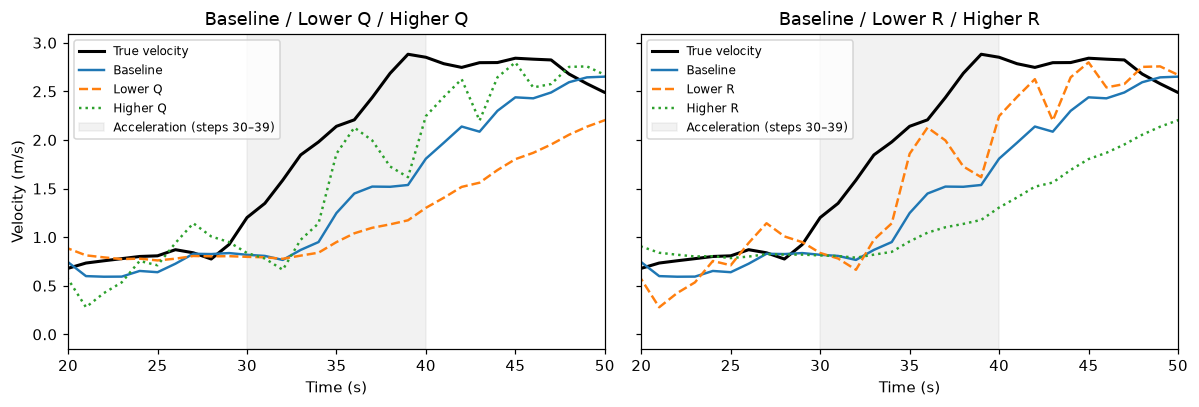

In [24]:
settings = [
    ("Baseline", 1.0, 1.0),
    ("Lower Q", 0.1, 1.0),
    ("Higher Q", 10.0, 1.0),
    ("Lower R", 1.0, 0.1),
    ("Higher R", 1.0, 10.0),
]

# Your code: run all five settings, create noise_results and plot the comparisons.
noise_runs = {}
rows = []
for name, q_mult, r_mult in settings:
    means, covs = run_kf(z_position, F, H, q_mult * Q_base, r_mult * R_base, mu0, P0)
    noise_runs[name] = means
    sd = np.sqrt(covs[1:, 0, 0])
    lower = means[1:, 0] - 1.96 * sd
    upper = means[1:, 0] + 1.96 * sd
    p_true = truth[1:, 0]
    rows.append({
        "setting": name,
        "position RMSE (m)": rmse(means[1:, 0], p_true),
        "velocity RMSE (m/s)": rmse(means[1:, 1], truth[1:, 1]),
        "mean position interval width (m)": np.mean(upper - lower),
        "position coverage (%)": 100 * np.mean((lower <= p_true) & (p_true <= upper)),
    })
noise_results = pd.DataFrame(rows)
display(noise_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
groups = [["Baseline", "Lower Q", "Higher Q"], ["Baseline", "Lower R", "Higher R"]]
styles = {"Baseline": "-", "Lower Q": "--", "Higher Q": ":",
          "Lower R": "--", "Higher R": ":"}
for ax, group in zip(axes, groups):
    ax.plot(time, truth[:, 1], color="black", lw=2, label="True velocity")
    for name in group:
        ax.plot(time, noise_runs[name][:, 1], styles[name], lw=1.6, label=name)
    ax.axvspan(30, 40, color="grey", alpha=0.1, label="Acceleration (steps 30–39)")
    ax.set(xlim=(20, 50), xlabel="Time (s)", title=" / ".join(group))
    ax.legend(fontsize=8)
axes[0].set_ylabel("Velocity (m/s)")
plt.tight_layout()
plt.show()

### Your answer — Task 2

1. Compare Lower Q with Higher Q during the first acceleration period. Which
   follows the changing velocity more quickly in the plot? Quote their
   **full-run velocity RMSE** values from `noise_results` and explain the role
   of the assumed process noise. No separate interval RMSE is required.
2. Compare Lower R with Higher R. Which run gives each new reading more weight?
   Support your explanation with the plot and their **full-run position RMSE** values.
3. Find the setting with the narrowest mean position interval. Report its width,
   coverage and position RMSE. Does a narrower interval alone establish greater
   accuracy? Explain using your table.

**1.** **Higher Q** follows the changing velocity much more quickly: at t = 40 s it
estimates 2.25 m/s against Lower Q's 1.30 m/s (truth 2.85 m/s). Full-run velocity RMSE is
**0.4 m/s for Higher Q** and **0.611 m/s for Lower Q** (Baseline 0.437 m/s). Q states how
far the real motion may depart from the constant-velocity model each step. A larger Q
inflates P(bar), which raises the gain, so innovations caused by the unmodelled acceleration
change the velocity estimate faster. A small Q tells the filter to trust its model and
smooth heavily, so it lags. The price of Higher Q is a noisier estimate (visible wiggles
around t = 20–33 s, before the acceleration).

**2.** **Lower R** gives each new reading more weight: a smaller R gives a smaller S and a
larger gain. In the plot, Lower R reacts to the acceleration early but jumps more from
step to step; Higher R is smooth but lags strongly (1.31 m/s at t = 40 s). Full-run
position RMSE is **1.239 m for Lower R** and **2.776 m for Higher R**. Lower R did better
here even though the true sensor variance is 4, because the constant-velocity model is
wrong during the accelerations, so recent readings are more useful than the model
assumes. Higher Q and Lower R have the same Q/R ratio, which is why their estimates are
nearly identical.

**3.** The narrowest interval belongs to **Lower R**: mean width **1.732 m**, coverage
**49.6%**, position RMSE **1.239 m**. A narrow interval alone does not establish greater
accuracy. Higher Q has almost the same RMSE (1.249 m) but an interval three times wider
(5.437 m) with 95.0% coverage; Lower R's band is narrow only because it assumes the sensor
is far more precise (SD 0.63 m instead of 2 m), so it misses the true position about half
the time. Lower Q is also narrower than Baseline (3.429 m) but has the worst RMSE
(2.739 m) and 55.5% coverage. Width reports the filter's assumed uncertainty, so it must
be checked against actual error and coverage.

## Task 3 — lose the position signal, then recover it

**Question:** What happens when the vehicle moves without new measurements?

The position sensor is unavailable at steps **30–44 inclusive**. The first
returning reading is at step **45**. Keep the baseline Q, R, initial belief
and all other readings unchanged. Do not use your best Task 2 setting here.

**Your code:** modify your original `run_kf` function in Task 1:

- Always perform prediction at each step.
- If `np.isnan(z[t])`, keep the predicted mean and covariance as the current
  belief. **Skip correction.** Otherwise, correct as before.
- Store a result at every step. Do not replace missing readings with zero,
  truth, the previous reading or an interpolation.

Edit the existing function cell rather than adding a second definition below.
Then rerun that cell and Task 1's baseline call. Results with complete
measurements must remain unchanged. The provided cell below creates a separate
copy with missing readings, so `z_position` stays intact.

**Required outputs:**

1. Run the modified filter on `z_missing`. Keep the outputs as `gap_means` and
   `gap_covariances`.
2. One figure with **two panels** for times **20–60 s**. First: truth, complete-data
   KF and missing-data KF positions, with the missing-data KF's 95% band.
   Second: position standard deviation for both filters. Shade the missing
   interval using `ax.axvspan(30, 45, alpha=0.1)`.
3. A table of position RMSE for both filters over **three separate periods**:
   Before (steps 1–29, slice `[1:30]`), Missing (30–44, `[30:45]`),
   After (45–119, `[45:]`).
4. A two-row table for the missing-data run at steps **44 and 45**, containing
   step, absolute position error (m), and position standard deviation (m).

Both filters must be evaluated against the same true positions in each period.
Their stored estimates before the outage should agree. At step 44, the stored
result is prediction-only; at step 45, it includes the returning measurement's
correction. Keep covariance propagation active during the gap, not just mean prediction.


In [25]:
z_missing = z_position.copy()
z_missing[30:45] = np.nan
print("Missing readings:", np.isnan(z_missing).sum())


Missing readings: 15


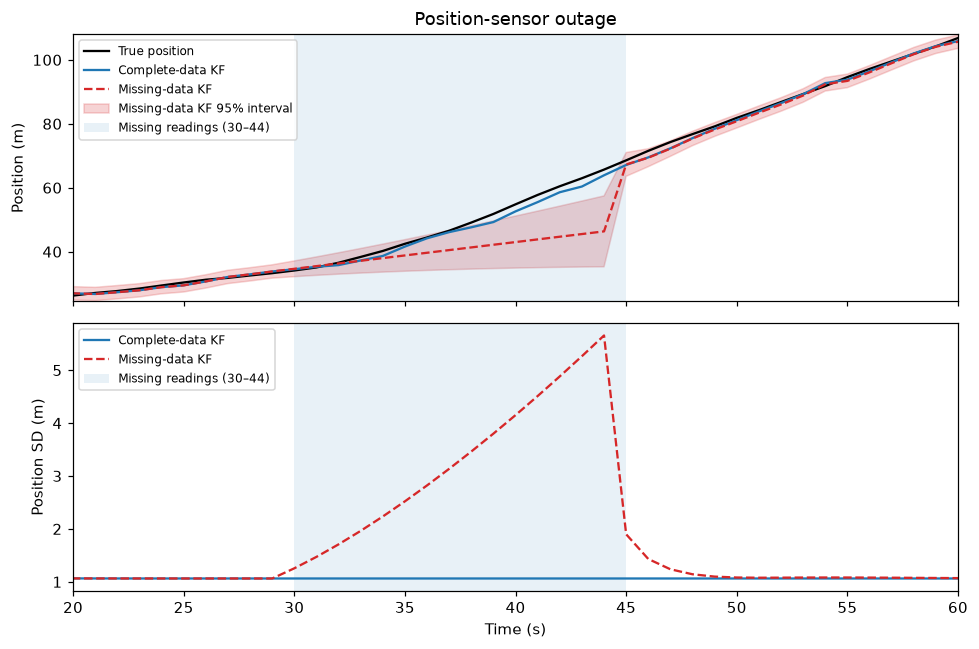

,period,complete-data KF position RMSE (m),missing-data KF position RMSE (m)
0,Before (1–29),1.299,1.299
1,Missing (30–44),1.579,9.977
2,After (45–119),1.329,1.353


,step,absolute position error (m),position SD (m)
0,44,19.322,5.656
1,45,1.282,1.899


In [26]:
# Your code: run the gap experiment, create both tables and plot both panels.
# First update and rerun the run_kf definition in Task 1.
gap_means, gap_covariances = run_kf(z_missing, F, H, Q_base, R_base, mu0, P0)

# Sanity checks: estimates agree before the outage; complete-data run unchanged.
assert np.allclose(gap_means[:30], kf_means[:30])
assert np.allclose(run_kf(z_position, F, H, Q_base, R_base, mu0, P0)[0], kf_means)

full_sd = np.sqrt(kf_covariances[:, 0, 0])
gap_sd = np.sqrt(gap_covariances[:, 0, 0])

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax = axes[0]
ax.plot(time, truth[:, 0], color="black", label="True position")
ax.plot(time, kf_means[:, 0], color="tab:blue", label="Complete-data KF")
ax.plot(time, gap_means[:, 0], "--", color="tab:red", label="Missing-data KF")
ax.fill_between(time, gap_means[:, 0] - 1.96 * gap_sd, gap_means[:, 0] + 1.96 * gap_sd,
                color="tab:red", alpha=0.2, label="Missing-data KF 95% interval")
ax.axvspan(30, 45, alpha=0.1, label="Missing readings (30–44)")
w = (time >= 20) & (time <= 60)
ax.set(ylabel="Position (m)", title="Position-sensor outage")
ax.set_ylim((gap_means[w, 0] - 2.2 * gap_sd[w]).min(), (gap_means[w, 0] + 2.2 * gap_sd[w]).max())
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
ax.plot(time, full_sd, color="tab:blue", label="Complete-data KF")
ax.plot(time, gap_sd, "--", color="tab:red", label="Missing-data KF")
ax.axvspan(30, 45, alpha=0.1, label="Missing readings (30–44)")
ax.set(xlim=(20, 60), xlabel="Time (s)", ylabel="Position SD (m)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

periods = [("Before (1–29)", slice(1, 30)), ("Missing (30–44)", slice(30, 45)),
           ("After (45–119)", slice(45, None))]
gap_rmse_table = pd.DataFrame({
    "period": [p for p, _ in periods],
    "complete-data KF position RMSE (m)": [rmse(kf_means[s, 0], truth[s, 0]) for _, s in periods],
    "missing-data KF position RMSE (m)": [rmse(gap_means[s, 0], truth[s, 0]) for _, s in periods],
})
display(gap_rmse_table.round(3))

steps = [44, 45]
return_table = pd.DataFrame({
    "step": steps,
    "absolute position error (m)": [abs(gap_means[t, 0] - truth[t, 0]) for t in steps],
    "position SD (m)": [gap_sd[t] for t in steps],
})
display(return_table.round(3))


### Your answer — Task 3

1. Compare the two filters' position RMSE during the outage. Use the velocity
   change during this interval to explain why prediction alone can become poor.
2. How does position uncertainty change during the gap? Explain why both the
   mean and covariance must be predicted even when there is no measurement.
3. Use the step-44/45 table to describe what happens when the sensor returns.
   Distinguish the change in actual error from the change in reported uncertainty.
   Does one returning reading guarantee an accurate estimate?

**1.** During the outage (steps 30–44) the complete-data KF has a position RMSE of
**1.579 m**, while the missing-data KF has **9.977 m**; before the outage both are
identical (1.299 m). The vehicle accelerates during steps 30–39, so its true velocity
rises from 0.92 m/s (t = 29) to about 2.80 m/s (t = 44). Without readings, the filter
simply extrapolates its last velocity estimate (≈ 0.84 m/s), so the position falls
further behind every second; the error grows roughly quadratically to −19.3 m at step 44.

**2.** The position SD grows from **1.06 m** at step 29 to **5.66 m** at step 44, and grows
faster than linearly, because each prediction adds Q and also carries velocity
uncertainty into position (P(bar)_pp = P_pp + 2 delta_t P_pv + delta_t^2·P_vv + q_p). The mean must be
predicted so the estimate keeps moving with the vehicle; the covariance must be predicted
so the filter knows it is becoming less certain. This gives honest wider bands and makes
the gain large when readings return; without it the gain would stay at its steady value
(0.28) and the returning reading would be under-weighted. Even so, the band misses the
truth at steps 38–44, because the real acceleration is larger than Q allows.

**3.** At step 44 (prediction only) the absolute position error is **19.32 m** and the
reported SD is **5.66 m**; at step 45 (after the returning reading) the error is
**1.28 m** and the SD is **1.90 m**. The large predicted variance gives a position gain of
about 0.90, so the estimate jumps almost onto the reading. The actual error fell by about
93%, but the reported SD fell for a different reason: it depends only on P(bar), H and R, not
on the reading's value, so it records how much information was added, not how large the
error actually is. One reading does not guarantee accuracy: the reading itself has 2 m
noise, and the velocity estimate is still too low (2.17 vs 2.84 m/s at step 45), so the
error rises again to 2.16 m at step 46 and only settles after several more readings.



## Task 4 — replace the sensor and use an EKF

**Question:** Can two very different position estimates predict the same range readings?

Use the **same true trajectory**, but replace the position sensor with a range
sensor. The vehicle is at (pₜ, 0) and a fixed beacon is at (0, d), with
d = 20 m. The sensor measures their distance:

$$
z_t^{\mathrm{range}}=h(x_t)+e_t,\qquad
h(x_t)=\sqrt{p_t^2+d^2},\qquad e_t\sim\mathcal N(0,R).
$$

Position coordinates can be positive or negative: the road extends to both sides
of zero. The filter receives only range readings in this task, **not** position
readings. The simulation below supplies the new readings with standard deviation
2 m, independently of the position-sensor errors.
This is a new sensor experiment, not a KF-versus-EKF comparison on the same readings.

The motion model is unchanged, so reuse `predict`. The EKF linearizes the
measurement model at the **predicted mean**:

$$
H_t=\begin{bmatrix}
\dfrac{\bar\mu_{t,p}}{\sqrt{\bar\mu_{t,p}^2+d^2}}&0
\end{bmatrix}.
$$

The zero appears because range at this instant does not directly depend on velocity.
In code, use a separate variable such as `H_range` for this Jacobian. Recompute
it from `mu_pred` at every correction; do not reuse Task 1's fixed `H`.
Use

$$
\nu_t=z_t^{\mathrm{range}}-h(\bar\mu_t),\qquad
S_t=H_t\bar P_tH_t^T+R,\qquad K_t=\frac{\bar P_tH_t^T}{S_t}.
$$

The mean and covariance correction formulas are the same as in Task 1, with
Hₜ instead of H. **Use the nonlinear function to predict range, not the
Jacobian multiplied by the predicted mean:**

$$
\widehat z_t=h(\bar\mu_t),\qquad
\widehat z_t\ne H_t\bar\mu_t.
$$

No additional nonlinear motion model is needed.


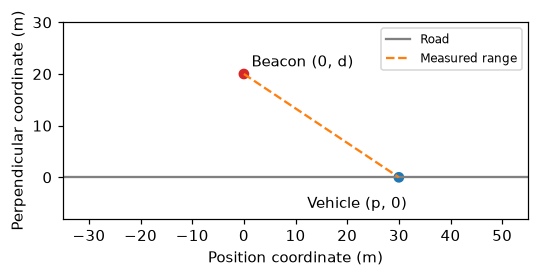

In [27]:
d = 20.0
rng_range = np.random.default_rng(SEED + 1)
true_range = np.sqrt(truth[:, 0]**2 + d**2)
z_range = true_range + rng_range.normal(0, sensor_sd, n_steps)

# Geometry only: the drawn vehicle is an example, not an extra observation.
fig, ax = plt.subplots(figsize=(5, 3))
ax.axhline(0, color="grey", label="Road")
ax.plot([0, 30], [d, 0], "--", color="tab:orange", label="Measured range")
ax.scatter([0, 30], [d, 0], color=["tab:red", "tab:blue"])
ax.annotate("Beacon (0, d)", (0, d), xytext=(5, 5), textcoords="offset points")
ax.annotate("Vehicle (p, 0)", (30, 0), xytext=(-60, -20), textcoords="offset points")
ax.set(xlim=(-35, 55), ylim=(-8, 30), xlabel="Position coordinate (m)",
       ylabel="Perpendicular coordinate (m)")
ax.set_aspect("equal")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


### 4A. Write the range correction and EKF loop

**Your code:** complete `correct_range`, returning the corrected mean and covariance.
Compute the predicted range, Jacobian, innovation, gain and correction explicitly.

Complete `run_ekf` by adapting your KF loop. Use `correct_range` instead of
`correct_position`. Return arrays with the same shapes and use the same time
convention: row 0 is the initial belief, then predict and correct at steps 1–119.
All range measurements are available; there is no outage in Task 4.

Keep the two loops short and separate. There is no need for classes or a general
filter framework. Do not force the position estimate to be positive.


In [28]:
def correct_range(mu_pred, P_pred, z, d, R):
    # Compute this step's range Jacobian from mu_pred, not Task 1's fixed H.
    # Return mu, P after using the range reading z.
    p = mu_pred[0]
    z_hat = np.sqrt(p**2 + d**2)                 # nonlinear predicted range h(mu_pred)
    H_range = np.array([p / z_hat, 0.0])         # Jacobian at the predicted mean
    innovation = z - z_hat
    S = H_range @ P_pred @ H_range + R
    K = P_pred @ H_range / S
    mu = mu_pred + K * innovation
    P = P_pred - np.outer(K, H_range @ P_pred)
    return mu, P


def run_ekf(z, F, Q, R, mu0, P0, d):
    # Reuse predict and call correct_range at each step.
    # Return means, covariances.
    n = len(z)
    means = np.zeros((n, 2))
    covariances = np.zeros((n, 2, 2))
    mu, P = mu0.copy(), P0.copy()
    means[0], covariances[0] = mu, P
    for t in range(1, n):
        mu, P = predict(mu, P, F, Q)
        mu, P = correct_range(mu, P, z[t], d, R)
        means[t], covariances[t] = mu, P
    return means, covariances


### One-step range check — provided code

This check starts from an already predicted belief. It uses a different beacon
distance from the main experiment. Do not call prediction again inside correction.


In [29]:
mu_check, P_check = correct_range(
    np.array([4.0, 1.0]), np.array([[1.0, 0.5], [0.5, 2.0]]),
    5.5, 3.0, 0.36
)
assert np.allclose(mu_check, [4.4, 1.2])
assert np.allclose(P_check, [[0.36, 0.18], [0.18, 1.84]])
print("One-step range check passed.")


One-step range check passed.


### 4B. Compare two initial beliefs — your code

Run the EKF twice on the **same** `z_range`:

- **Positive start:** close to the true initial position.
- **Negative start:** on the wrong side of the beacon for this trajectory.

The two initial means are

$$
\mu_0^{\mathrm{positive}}=\begin{bmatrix}8\\0\end{bmatrix},\qquad
\mu_0^{\mathrm{negative}}=\begin{bmatrix}-8\\0\end{bmatrix}.
$$

Use `P0`, `Q_base` and `R_base` in both runs. Only the initial mean changes.
Store the results as `positive_means`, `positive_covariances`, `negative_means`
and `negative_covariances`. Do not use the complete-data position KF to initialize them.

**Required outputs:**

1. `ekf_results`: one row per start, with position RMSE (m), velocity RMSE (m/s),
   **one-step range-prediction RMSE** (m), and position coverage (%).
   Position/velocity errors and coverage use the stored, corrected estimates.
   Position coverage uses each EKF run's approximate Gaussian interval as in Task 2.
2. One figure with **two panels**. First: true position and both estimated
   positions, with a shaded 95% band for each run. Second: measured ranges and
   both **one-step predicted ranges** against time.

For the range-prediction metric and plot, reconstruct each prediction from the
previous stored mean. For steps 1–119:

$$
\bar\mu_t=F\mu_{t-1},\qquad
\widehat z_t=h(\bar\mu_t)=\sqrt{\bar\mu_{t,p}^{\,2}+d^2}.
$$

Compare these predictions with `z_range[1:]`. Do **not** use the mean after
correction with the current reading. This metric checks predictions of **noisy
sensor readings**, while position and velocity RMSE compare estimates with truth.
Use `time[1:]` for the predicted-range plot.

The two predicted-range curves may overlap; use different line styles so this
is visible. Do not change data or settings to make one run look better.


,start,position RMSE (m),velocity RMSE (m/s),one-step range-prediction RMSE (m),position coverage (%)
0,Positive start,1.540,0.460,2.747,88.235
1,Negative start,236.039,3.339,2.747,0.000


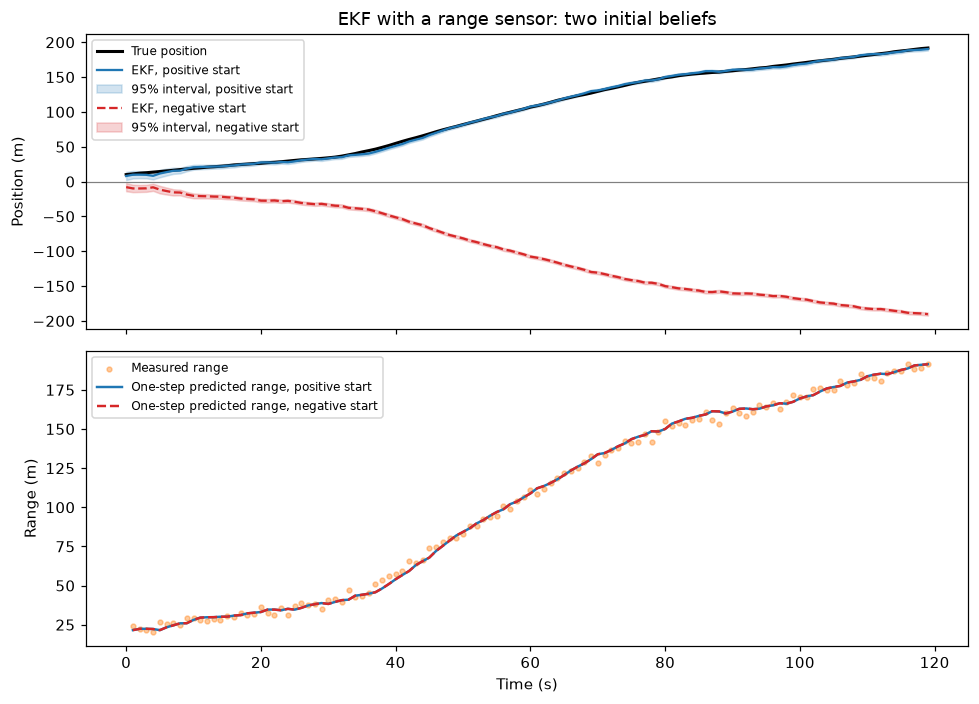

In [30]:
mu0_positive = np.array([8.0, 0.0])
mu0_negative = np.array([-8.0, 0.0])

# Your code: run both EKFs, create ekf_results and the two-panel figure.
# Reconstruct one-step predicted ranges from the previous corrected means.
positive_means, positive_covariances = run_ekf(z_range, F, Q_base, R_base, mu0_positive, P0, d)
negative_means, negative_covariances = run_ekf(z_range, F, Q_base, R_base, mu0_negative, P0, d)

def predicted_ranges(means):
    mu_bar = means[:-1] @ F.T                     # F mu_{t-1} for t = 1..119
    return np.sqrt(mu_bar[:, 0]**2 + d**2)

runs = {"Positive start": (positive_means, positive_covariances),
        "Negative start": (negative_means, negative_covariances)}
rows, pred_range = [], {}
for name, (means, covs) in runs.items():
    pred_range[name] = predicted_ranges(means)
    sd = np.sqrt(covs[1:, 0, 0])
    lower, upper = means[1:, 0] - 1.96 * sd, means[1:, 0] + 1.96 * sd
    p_true = truth[1:, 0]
    rows.append({
        "start": name,
        "position RMSE (m)": rmse(means[1:, 0], p_true),
        "velocity RMSE (m/s)": rmse(means[1:, 1], truth[1:, 1]),
        "one-step range-prediction RMSE (m)": rmse(pred_range[name], z_range[1:]),
        "position coverage (%)": 100 * np.mean((lower <= p_true) & (p_true <= upper)),
    })
ekf_results = pd.DataFrame(rows)
display(ekf_results.round(3))

fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
ax = axes[0]
ax.plot(time, truth[:, 0], color="black", lw=2, label="True position")
colors = {"Positive start": "tab:blue", "Negative start": "tab:red"}
lines = {"Positive start": "-", "Negative start": "--"}
for name, (means, covs) in runs.items():
    sd = np.sqrt(covs[:, 0, 0])
    ax.plot(time, means[:, 0], lines[name], color=colors[name], label=f"EKF, {name.lower()}")
    ax.fill_between(time, means[:, 0] - 1.96 * sd, means[:, 0] + 1.96 * sd,
                    color=colors[name], alpha=0.2, label=f"95% interval, {name.lower()}")
ax.axhline(0, color="grey", lw=0.8)
ax.set(ylabel="Position (m)", title="EKF with a range sensor: two initial beliefs")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
ax.scatter(time[1:], z_range[1:], s=10, alpha=0.4, color="tab:orange", label="Measured range")
for name in runs:
    ax.plot(time[1:], pred_range[name], lines[name], color=colors[name], lw=1.6,
            label=f"One-step predicted range, {name.lower()}")
ax.set(xlabel="Time (s)", ylabel="Range (m)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### Your answer — Task 4

1. Quote position RMSE and one-step range-prediction RMSE for both starts.
   Which differences are large, and which are small? Use the two panels and
   the range function to explain the comparison.
2. Compare position coverage for the two starts. Why is the negative-start
   result not evidence that the sensor has located the vehicle correctly,
   even if its reported interval is narrow? Refer to the range function and
   the initial beliefs. State one extra piece of information that could
   distinguish the two sides of the beacon.
3. In your code, identify where the Jacobian is used and where the nonlinear
   function is used. Why would replacing the predicted range by
   `H_range @ mu_pred` give a different, incorrect innovation? Here `H_range`
   means the range Jacobian at that step, not Task 1's position-sensor matrix.

**1.** Position RMSE: **1.540 m** (positive start) versus **236.04 m** (negative start), a
huge difference. One-step range-prediction RMSE: **2.747 m** for both, so no difference.
The first panel shows the negative-start estimate as a mirror image of the truth (it
tracks −pₜ, reaching about −190 m), while in the second panel both predicted-range curves
lie on top of each other and follow the measured ranges. Because h(p) = √(p² + d²)
depends only on p², h(−p) = h(p): an estimate on the wrong side predicts exactly the same
readings. (In this run the negative-start means are exactly −1 × the positive-start
means.)

**2.** Position coverage is **88.2%** for the positive start and **0.0%** for the negative
start. The negative run still reports a narrow band (mean SD ≈ 1.24 m, identical to the
positive run) because the EKF covariance depends on the squared Jacobian, which is the same
on both sides. Its small range errors only show that it is consistent with the readings,
not that it has found the vehicle: the range cannot tell +p from −p, so the side is decided
entirely by the initial belief. P₀ gives an SD of 3 m around −8 m, so it puts almost no
probability on the true side, and linearizing at the predicted mean keeps the filter on
that branch. Extra information such as a second beacon not on the y-axis (e.g. at (15, 20)
m), a bearing (left/right) measurement, or a single position fix or known direction of
travel at the start would break the symmetry.

**3.** In correct_range, the nonlinear function is used for the predicted range,
z_hat = np.sqrt(p**2 + d**2), and therefore the innovation z - z_hat. The Jacobian
H_range = [p / z_hat, 0] is used only for uncertainty: S = H_range @ P_pred @ H_range + R,
the gain K = P_pred @ H_range / S and the covariance update
np.outer(K, H_range @ P_pred). The linearization is a tangent line,
h(x) ≈ h(μ̄) + H(x − μ̄), which does not pass through the origin, so H μ(bar) = p^2/sqrt(p^2 + d^2)
= h(μ(bar)) − d²/h(μ(bar) omits the intercept. For example, at p = 10 m, h(μ(bar)) = 22.36 m but
H μ(bar) = 4.47 m, so the innovation would be inflated by about 17.9 m at every step and pull
the estimate badly off. H @ mu is only valid for a linear sensor such as Task 1's.


## Before submission

- Complete all four tasks, including their implementation, required tables,
  figures and numbered answers. These are the full task requirements.
- Keep provided data generation unchanged. Do not pass true states or the
  supplied acceleration sequence into a filter.
- Check that Task 3's missing-reading change still works on complete data.
- Restart the kernel and run the completed notebook from top to bottom. There
  should be no unfinished function stubs or reliance on cells run out of order.
- Keep your explanations beside the relevant results. Saving outputs helps the
  reader, but a missing saved output is not itself an error in your method.
- Submit **this completed notebook only**, using the Moodle activity and deadline
  given by the lecturer. No separate report or results spreadsheet is required.

### Use of external help

Briefly state any AI tools or other sources you used, what they helped with,
and how you checked the resulting code or explanations. Write “None” if you
used none. You are responsible for understanding the submitted work.

**Your disclosure:** Claude + Gemini
graphs, plots, long codes corrections. Explaining the outputs and the syntax of the functions.
